In [1]:
import sys

print("Python:", sys.version.split()[0])

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch is not installed yet.")

Python: 3.13.16
PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [2]:
from PIL import Image
import torchvision

print("Pillow:", Image.__version__ if hasattr(Image, "__version__") else "ready")
print("Torchvision:", torchvision.__version__)

Pillow: 11.3.0
Torchvision: 0.29.1+cu130


### Set up the project folders


In [3]:
from pathlib import Path

PROJECT_DIR = Path("/content/face_recognition_project")
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in (DATA_DIR, MODEL_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Created:", ", ".join(folder.name for folder in PROJECT_DIR.iterdir()))

Project folder: /content/face_recognition_project
Created: results, models, data


In [4]:
for name, folder in [
    ("Data", DATA_DIR),
    ("Models", MODEL_DIR),
    ("Results", RESULTS_DIR),
]:
    print(f"{name}: {folder} — exists: {folder.exists()}")

Data: /content/face_recognition_project/data — exists: True
Models: /content/face_recognition_project/models — exists: True
Results: /content/face_recognition_project/results — exists: True


In [5]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

print("Accepted formats:", ", ".join(sorted(IMAGE_EXTENSIONS)))

Accepted formats: .jpeg, .jpg, .png


In [6]:
PARTICIPANTS = [f"P{i:02d}" for i in range(1, 6)]

print("Participant labels:", PARTICIPANTS)

Participant labels: ['P01', 'P02', 'P03', 'P04', 'P05']


In [7]:
for participant in PARTICIPANTS:
    (DATA_DIR / participant).mkdir(parents=True, exist_ok=True)

print("Participant folders:")
for participant in PARTICIPANTS:
    print(DATA_DIR / participant)

Participant folders:
/content/face_recognition_project/data/P01
/content/face_recognition_project/data/P02
/content/face_recognition_project/data/P03
/content/face_recognition_project/data/P04
/content/face_recognition_project/data/P05


In [8]:
for participant in PARTICIPANTS:
    folder = DATA_DIR / participant
    images = [
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    ]
    print(f"{participant}: {len(images)} images")

P01: 0 images
P02: 0 images
P03: 0 images
P04: 0 images
P05: 0 images


In [9]:
from PIL import Image

def inspect_image(image_path):
    try:
        with Image.open(image_path) as image:
            image.verify()

        with Image.open(image_path) as image:
            return {
                "valid": True,
                "size": image.size,
                "mode": image.mode,
            }
    except Exception as error:
        return {
            "valid": False,
            "error": str(error),
        }

print("Image inspection function is ready.")

Image inspection function is ready.


In [10]:
def check_participant_images(participant):
    folder = DATA_DIR / participant
    images = sorted(
        file for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"\n{participant}: {len(images)} image(s)")
    for image_path in images:
        result = inspect_image(image_path)
        if result["valid"]:
            print(f"  OK  {image_path.name}: {result['size']}")
        else:
            print(f"  BAD {image_path.name}: {result['error']}")

print("Photo check is ready. We’ll run it after adding the pictures.")

Photo check is ready. We’ll run it after adding the pictures.


In [11]:
IMAGE_SIZE = (160, 160)

print("Model image size:", IMAGE_SIZE)

Model image size: (160, 160)


In [12]:
BATCH_SIZE = 16
EPOCHS = 15
LEARNING_RATE = 0.001
VALIDATION_FRACTION = 0.2

print("Batch size:", BATCH_SIZE)
print("Training rounds:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Validation fraction:", VALIDATION_FRACTION)

Batch size: 16
Training rounds: 15
Learning rate: 0.001
Validation fraction: 0.2


In [13]:
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
])

print("Image transform is ready.")

Image transform is ready.


### Define the CNN
Creates a small convolutional neural network with one output per participant. It defines the model, without training.

In [14]:
import torch
import torch.nn as nn

class FaceCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Linear(128, num_classes)

    def forward(self, images):
        features = self.features(images)
        features = torch.flatten(features, start_dim=1)
        return self.classifier(features)

NUM_CLASSES = len(PARTICIPANTS)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FaceCNN(NUM_CLASSES).to(device)

print("Model ready:", NUM_CLASSES, "participant classes")
print("Device:", device)

Model ready: 5 participant classes
Device: cuda


### Set up the training tools
This prepares the loss function and optimizer the CNN will use during training.

In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function and optimizer are ready.")

Loss function and optimizer are ready.


### Prepare a training function
This function will train the model for one pass through the training data and report its average loss.

In [16]:
def train_one_epoch(model, data_loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_images = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        predictions = model(images)
        loss = criterion(predictions, labels)
        loss.backward()
        optimizer.step()

        batch_count = images.size(0)
        total_loss += loss.item() * batch_count
        total_images += batch_count

    return total_loss / total_images

### Step 18 — Prepare an accuracy check
This defines a function to measure how often the model predicts the correct participant.

In [17]:
def evaluate_model(model, data_loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return correct / total if total else 0.0

### Prepare the training loop
This will train the CNN for the number of rounds you set earlier and report training loss and validation accuracy each round.

In [18]:
def train_model(
    model,
    train_loader,
    validation_loader,
    criterion,
    optimizer,
    device,
    epochs,
):
    history = []

    for epoch in range(epochs):
        loss = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )
        accuracy = evaluate_model(model, validation_loader, device)

        history.append({
            "epoch": epoch + 1,
            "loss": loss,
            "validation_accuracy": accuracy,
        })

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"| loss: {loss:.4f} "
            f"| validation accuracy: {accuracy:.1%}"
        )

    return history

### Prepare to save the model
This defines a function to save the trained model and participant labels in the models folder.

In [19]:
import json

def save_model(model, model_dir, participants):
    model_dir.mkdir(parents=True, exist_ok=True)

    model_path = model_dir / "face_cnn.pth"
    labels_path = model_dir / "participant_labels.json"

    torch.save(model.state_dict(), model_path)
    labels_path.write_text(
        json.dumps(participants, indent=2),
        encoding="utf-8",
    )

    print("Model saved to:", model_path)
    print("Labels saved to:", labels_path)

### Prepare to load the saved model
This function will restore the trained model and its participant labels.

In [20]:
def load_model(model_path, labels_path, device):
    participants = json.loads(labels_path.read_text(encoding="utf-8"))

    loaded_model = FaceCNN(num_classes=len(participants)).to(device)
    state = torch.load(model_path, map_location=device)
    loaded_model.load_state_dict(state)
    loaded_model.eval()

    return loaded_model, participants

print("Model loading function is ready.")

Model loading function is ready.


### Prepare a prediction function
This function will take one image and return the participant label with the highest model score.

In [21]:
def predict_image(model, image_path, participants, device):
    image = Image.open(image_path).convert("RGB")
    image_tensor = image_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        scores = model(image_tensor)
        predicted_index = scores.argmax(dim=1).item()

    return participants[predicted_index]

print("Prediction function is ready.")

Prediction function is ready.


### Prepare an image preview
This function will display a photo from a participant’s folder with its filename.

In [22]:
import matplotlib.pyplot as plt

def show_image(image_path):
    image = Image.open(image_path).convert("RGB")
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

print("Image preview function is ready.")

Image preview function is ready.


### Prepare the image dataset loader
This function will load photos from the participant folders and attach each folder’s label.

In [23]:
from torchvision.datasets import ImageFolder

def load_image_dataset():
    dataset = ImageFolder(
        DATA_DIR,
        transform=image_transform,
        allow_empty=True,
    )

    if not dataset.samples:
        print("No photos found yet. Add images to the P01–P05 folders when ready.")
        return None

    print("Images loaded:", len(dataset))
    print("Folder labels:", dataset.class_to_idx)
    return dataset

dataset = load_image_dataset()

No photos found yet. Add images to the P01–P05 folders when ready.


### Prepare the data loaders
This function will split the photos into training and validation sets and group them into batches.

In [24]:
from torch.utils.data import DataLoader, random_split

def make_data_loaders(dataset):
    if dataset is None or len(dataset) == 0:
        print("Waiting for photos before creating data loaders.")
        return None, None

    validation_size = round(len(dataset) * VALIDATION_FRACTION)
    training_size = len(dataset) - validation_size

    training_set, validation_set = random_split(
        dataset,
        [training_size, validation_size],
        generator=torch.Generator().manual_seed(42),
    )

    training_loader = DataLoader(
        training_set,
        batch_size=BATCH_SIZE,
        shuffle=True,
    )
    validation_loader = DataLoader(
        validation_set,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    print("Training images:", training_size)
    print("Validation images:", validation_size)
    return training_loader, validation_loader

train_loader, validation_loader = make_data_loaders(dataset)

Waiting for photos before creating data loaders.


### Prepare a full photo check
This function will check all five participant folders for readable images and show each person’s image count.

In [25]:
def check_all_participants():
    for participant in PARTICIPANTS:
        check_participant_images(participant)

print("Full photo check is ready.")

Full photo check is ready.


### Prepare the training run
This function will create the data loaders, train the model, and return the training history.

In [26]:
def run_training():
    dataset = load_image_dataset()

    if dataset is None:
        print("Training has not started. Add photos first.")
        return None

    train_loader, validation_loader = make_data_loaders(dataset)

    if train_loader is None:
        return None

    history = train_model(
        model,
        train_loader,
        validation_loader,
        criterion,
        optimizer,
        device,
        EPOCHS,
    )
    return history

print("Training function is ready.")

Training function is ready.


### Prepare to plot training progress
This function will plot the training loss and validation accuracy after training.

In [27]:
def plot_training_history(history):
    if not history:
        print("No training history to plot yet.")
        return

    epochs = [item["epoch"] for item in history]
    losses = [item["loss"] for item in history]
    accuracies = [item["validation_accuracy"] for item in history]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, losses, marker="o")
    axes[0].set_title("Training loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")

    axes[1].plot(epochs, accuracies, marker="o")
    axes[1].set_title("Validation accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_ylim(0, 1)

    plt.tight_layout()
    plt.show()

print("Training plot function is ready.")

Training plot function is ready.


### Check face detection support

In [28]:
import cv2

face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

print("OpenCV:", cv2.__version__)
print("Face detector ready:", not face_detector.empty())

OpenCV: 4.14.0
Face detector ready: True


### Prepare face cropping
This function will find the largest front-facing face in a photo and crop around it.

In [29]:
def crop_largest_face(image):
    image = image.convert("RGB")
    image_array = cv2.cvtColor(
        __import__("numpy").array(image),
        cv2.COLOR_RGB2BGR,
    )
    gray = cv2.cvtColor(image_array, cv2.COLOR_BGR2GRAY)

    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40),
    )

    if len(faces) == 0:
        raise ValueError("No front-facing face detected in this image.")

    x, y, width, height = max(
        faces,
        key=lambda box: box[2] * box[3],
    )

    return image.crop((x, y, x + width, y + height))

print("Face-cropping function is ready.")

Face-cropping function is ready.


### Check face detection support

In [30]:
image_transform = transforms.Compose([
    transforms.Lambda(crop_largest_face),
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
])

print("Face-crop preprocessing is ready.")

Face-crop preprocessing is ready.


### Prepare a face detection check
This function will report how many faces the detector finds in a photo.

In [31]:
def count_faces(image_path):
    image = Image.open(image_path).convert("RGB")
    image_array = __import__("numpy").array(image)
    gray = cv2.cvtColor(image_array, cv2.COLOR_RGB2GRAY)

    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40),
    )

    return len(faces)

print("Face detection check is ready.")

Face detection check is ready.


### Prepare a face count report
This function will count detected faces in each photo and flag images where the detector finds none or more than one.

In [32]:
def check_all_faces():
    for participant in PARTICIPANTS:
        folder = DATA_DIR / participant
        images = sorted(
            file for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        print(f"\n{participant}:")
        for image_path in images:
            try:
                face_count = count_faces(image_path)
                status = "OK" if face_count == 1 else "CHECK"
                print(f"  {status} {image_path.name}: {face_count} face(s)")
            except Exception as error:
                print(f"  BAD {image_path.name}: {error}")

print("Face count report is ready.")

Face count report is ready.


### Prepare to save training progress
This function will save the training history as a CSV file in the results folder after training.

In [33]:
import csv

def save_training_history(history):
    if not history:
        print("No training history to save.")
        return

    history_path = RESULTS_DIR / "training_history.csv"

    with history_path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(
            file,
            fieldnames=["epoch", "loss", "validation_accuracy"],
        )
        writer.writeheader()
        writer.writerows(history)

    print("Training history saved to:", history_path)

print("Training history saver is ready.")

Training history saver is ready.


### Prepare the results export

In [34]:
def save_training_results(history):
    if not history:
        print("Nothing to save yet.")
        return

    save_model(model, MODEL_DIR, PARTICIPANTS)
    save_training_history(history)

print("Results export is ready.")

Results export is ready.


### Prepare the attendance log
This function will add a participant and timestamp to a CSV attendance log when the trained model recognizes a photo.

In [35]:
from datetime import datetime

ATTENDANCE_FILE = RESULTS_DIR / "attendance.csv"

def record_attendance(image_path, model, participants, device):
    participant = predict_image(model, image_path, participants, device)
    timestamp = datetime.now().isoformat(timespec="seconds")
    file_exists = ATTENDANCE_FILE.exists()

    with ATTENDANCE_FILE.open("a", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        if not file_exists:
            writer.writerow(["timestamp", "participant", "image"])
        writer.writerow([timestamp, participant, Path(image_path).name])

    print(f"Attendance recorded: {participant} at {timestamp}")

print("Attendance logger is ready.")

Attendance logger is ready.


### Prepare photo upload

In [36]:
import zipfile
from google.colab import files

def upload_photo_zip():
    uploaded = files.upload()

    zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(zip_names) != 1:
        print("Please upload one ZIP file containing the P01–P05 folders.")
        return

    zip_path = Path("/content") / zip_names[0]

    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(DATA_DIR)

    print("ZIP extracted to:", DATA_DIR)
    print("Next, check that P01–P05 folders are inside the data folder.")

print("Photo upload function is ready.")

Photo upload function is ready.


### Check the uploaded folder layout
This function will show the folders and files directly inside the data folder.

In [37]:
def show_data_folder():
    if not DATA_DIR.exists():
        print("Data folder not found:", DATA_DIR)
        return

    for path in sorted(DATA_DIR.iterdir()):
        kind = "folder" if path.is_dir() else "file"
        print(f"{kind}: {path.name}")

print("Folder layout check is ready.")

Folder layout check is ready.


### Prepare a photo count check
This will count photos in each participant folder and show whether each has the expected 60.

In [38]:
EXPECTED_IMAGES_PER_PERSON = 60

def check_photo_counts():
    for participant in PARTICIPANTS:
        folder = DATA_DIR / participant
        count = sum(
            1 for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        ) if folder.exists() else 0

        status = "OK" if count == EXPECTED_IMAGES_PER_PERSON else "CHECK"
        print(f"{status} {participant}: {count}/{EXPECTED_IMAGES_PER_PERSON}")

print("Photo count check is ready.")

Photo count check is ready.


### Upload ZIP to Colab
After having collected data from my partcipants with consent, now i upload my data.

In [39]:
upload_photo_zip()

Saving participants.zip.zip to participants.zip.zip
ZIP extracted to: /content/face_recognition_project/data
Next, check that P01–P05 folders are inside the data folder.


In [40]:
show_data_folder()

folder: P01
folder: P02
folder: P03
folder: P04
folder: P05


# Analysis plan
 I will check image counts, readability, dimensions, and face detection for each participant. I will visualize the dataset balance and review sample images. I will use up to 60 images per participant to create face profiles. I will evaluate recognition on fresh photos that were not used to create those profiles, report correct and incorrect matches, and discuss the small dataset and similarity cutoff as limitations.

,participant,total_images,readable_images,unreadable_images,median_width,median_height
0,P01,70,70,0,372,497
1,P02,81,81,0,959,1280
2,P03,100,100,0,1737,3088
3,P04,60,60,0,972,1296
4,P05,71,71,0,972,1296


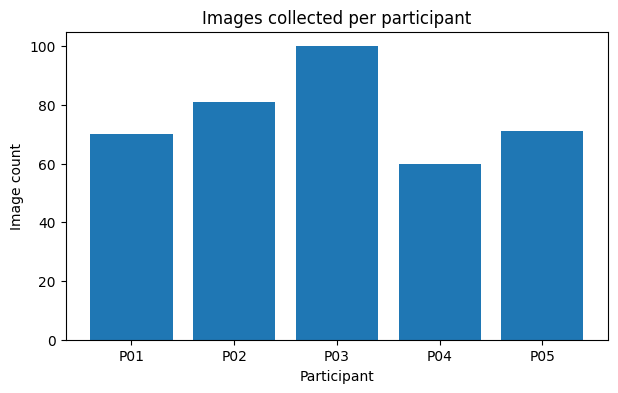

In [85]:
import pandas as pd
import matplotlib.pyplot as plt

eda_rows = []

for participant in PARTICIPANTS:
    folder = DATA_DIR / participant
    image_paths = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    readable = 0
    unreadable = 0
    widths, heights = [], []

    for image_path in image_paths:
        try:
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                width, height = image.size

            readable += 1
            widths.append(width)
            heights.append(height)
        except Exception:
            unreadable += 1

    eda_rows.append({
        "participant": participant,
        "total_images": len(image_paths),
        "readable_images": readable,
        "unreadable_images": unreadable,
        "median_width": int(pd.Series(widths).median()) if widths else None,
        "median_height": int(pd.Series(heights).median()) if heights else None,
    })

eda_table = pd.DataFrame(eda_rows)
display(eda_table)

eda_table.to_csv(RESULTS_DIR / "dataset_eda_summary.csv", index=False)

plt.figure(figsize=(7, 4))
plt.bar(eda_table["participant"], eda_table["total_images"])
plt.title("Images collected per participant")
plt.xlabel("Participant")
plt.ylabel("Image count")
plt.show()

# Dataset suitability
The dataset contains 382 smartphone photos from five consenting participants. The participant folders provide labels for supervised recognition. All 382 images opened successfully, with 60 to 100 images per participant. I will balance the enrollment profiles at 60 images per participant so no participant contributes more profile images than another.

The dataset is suitable for a small prototype that recognizes these five enrolled participants. It is limited in size and represents only these individuals and the conditions in their submitted photos. I did not record separate collection sessions, so I cannot evaluate performance on a session-based holdout. I will report results from fresh photos separately and treat them as a limited test.

#### Review a sample of the dataset

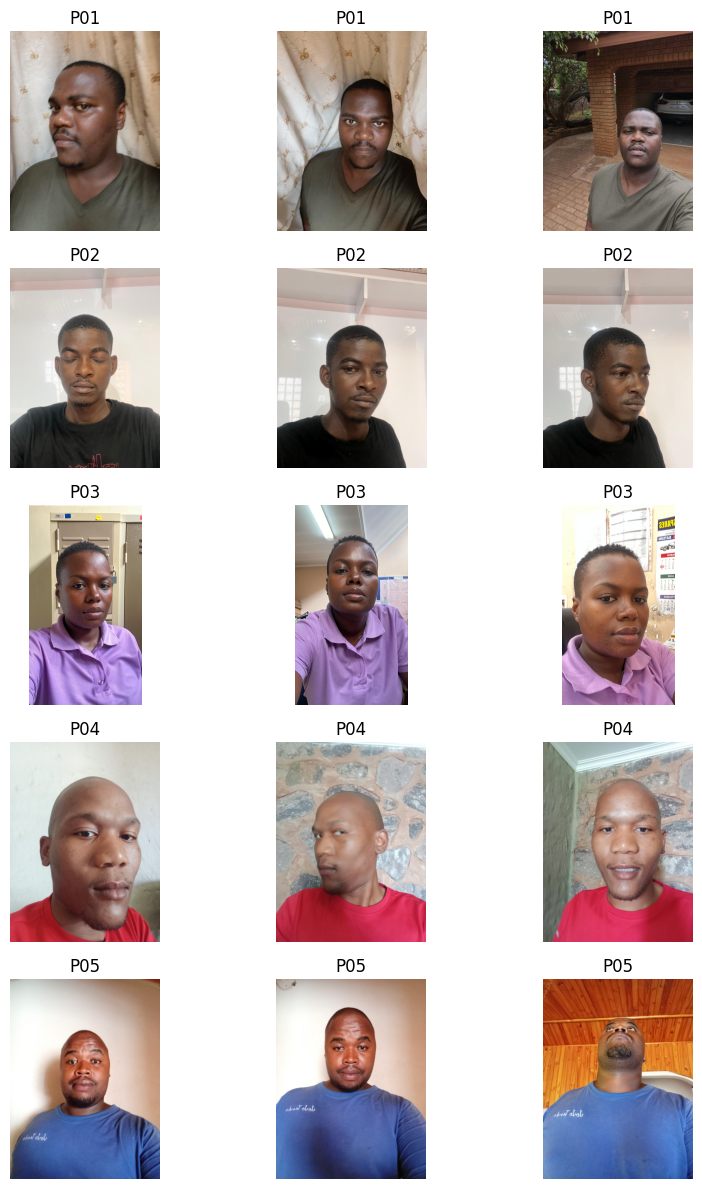

In [86]:
sample_rng = random.Random(17)
fig, axes = plt.subplots(len(PARTICIPANTS), 3, figsize=(9, 12))

for row, participant in enumerate(PARTICIPANTS):
    folder = DATA_DIR / participant
    images = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]
    selected = sample_rng.sample(images, min(3, len(images)))

    for col, image_path in enumerate(selected):
        with Image.open(image_path) as image:
            axes[row, col].imshow(image.convert("RGB"))
        axes[row, col].set_title(participant)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

Check photo counts

In [41]:
check_photo_counts()


CHECK P01: 70/60
CHECK P02: 81/60
CHECK P03: 100/60
OK P04: 60/60
CHECK P05: 71/60


Check that the photos open

In [42]:
for participant in PARTICIPANTS:
    folder = DATA_DIR / participant
    images = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    bad_images = [
        path.name for path in images
        if not inspect_image(path)["valid"]
    ]

    print(f"{participant}: {len(images) - len(bad_images)} readable"
          f" / {len(bad_images)} unreadable")
    if bad_images:
        print("  Unreadable:", bad_images)

P01: 70 readable / 0 unreadable
P02: 81 readable / 0 unreadable
P03: 100 readable / 0 unreadable
P04: 60 readable / 0 unreadable
P05: 71 readable / 0 unreadable


Check face detection

In [43]:
for participant in PARTICIPANTS:
    folder = DATA_DIR / participant
    images = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    needs_check = []
    for image_path in images:
        face_count = count_faces(image_path)
        if face_count != 1:
            needs_check.append((image_path.name, face_count))

    print(f"{participant}: {len(images) - len(needs_check)} with one face"
          f" / {len(needs_check)} to check")
    if needs_check:
        print("  Examples:", needs_check[:5])

P01: 47 with one face / 23 to check
  Examples: [('IMG20261117133115_tmp.jpg', 0), ('IMG20261117133303_tmp.jpg', 0), ('IMG20261117133105_tmp.jpg', 2), ('IMG20261117133102_tmp.jpg', 2), ('IMG20261117133111_tmp.jpg', 0)]
P02: 53 with one face / 28 to check
  Examples: [('IMG-20261117-WA0358.jpg', 0), ('IMG-20261117-WA0356.jpg', 2), ('IMG-20261117-WA0406.jpg', 0), ('IMG-20261117-WA0394.jpg', 0), ('IMG-20261117-WA0359.jpg', 0)]
P03: 57 with one face / 43 to check
  Examples: [('IMG-20261117-WA0162.jpg', 2), ('IMG-20261117-WA0194.jpg', 2), ('IMG-20261117-WA0071.jpg', 3), ('IMG-20261117-WA0293.jpg', 2), ('IMG-20261117-WA0264.jpg', 0)]
P04: 45 with one face / 15 to check
  Examples: [('IMG-20261117-WA0684.jpg', 0), ('IMG-20261117-WA0675.jpg', 0), ('IMG-20261117-WA0677.jpg', 0), ('IMG-20261117-WA0647.jpg', 0), ('IMG-20261117-WA0616.jpg', 2)]
P05: 37 with one face / 34 to check
  Examples: [('IMG-20261117-WA0741.jpg', 0), ('IMG-20261117-WA0501.jpg', 14), ('IMG-20261117-WA0750.jpg', 0), ('IMG-20

### Inspect a sample of flagged photos
This shows three photos per participant that the detector flagged. Check whether each photo clearly shows just that participant’s face; the automatic count can be wrong.

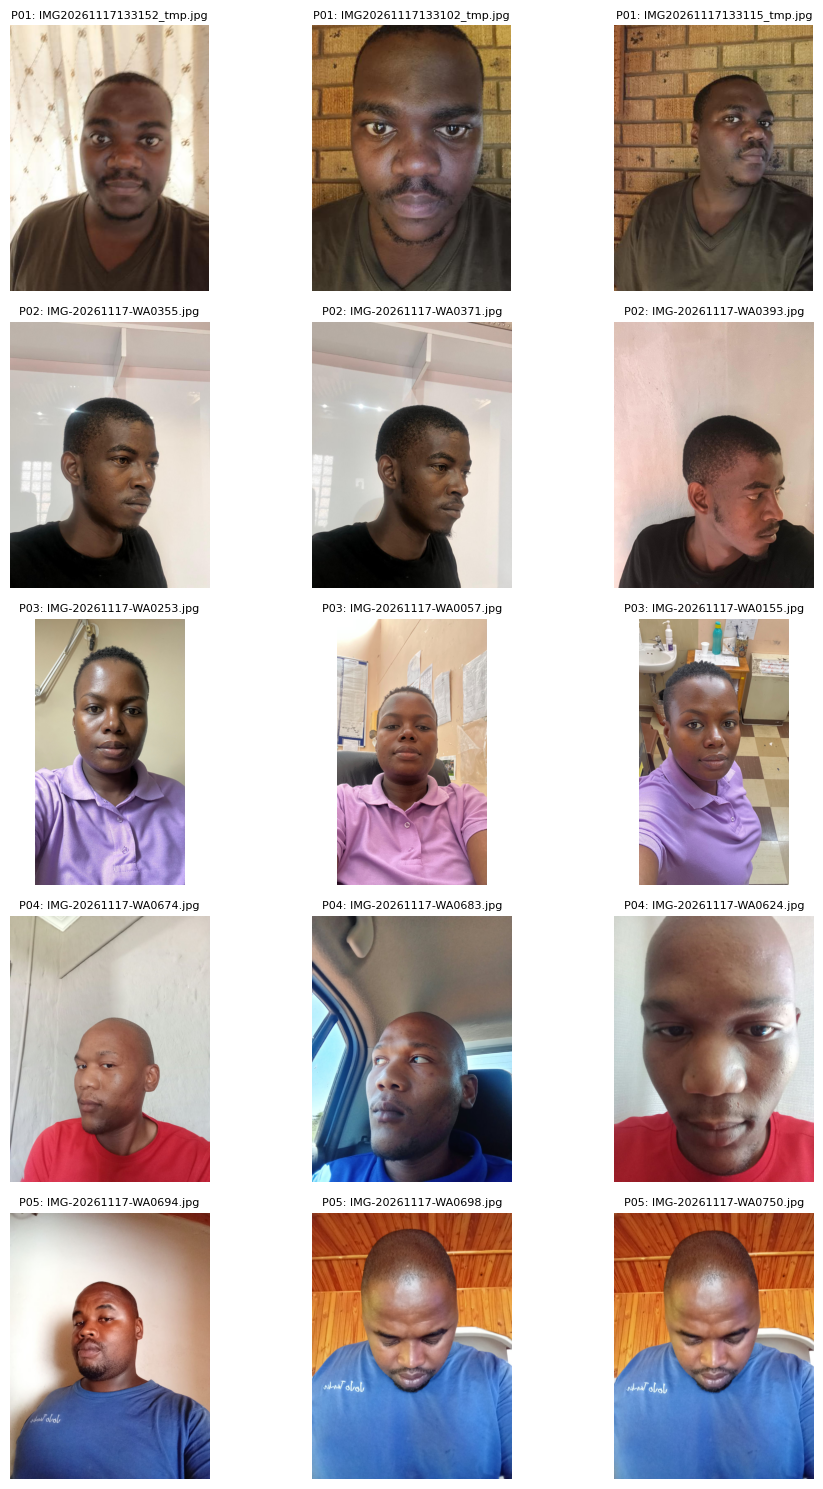

In [44]:
import random
import matplotlib.pyplot as plt

random.seed(42)
samples = []

for participant in PARTICIPANTS:
    folder = DATA_DIR / participant
    images = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]
    flagged = [path for path in images if count_faces(path) != 1]
    samples.extend(
        (participant, path)
        for path in random.sample(flagged, min(3, len(flagged)))
    )

fig, axes = plt.subplots(5, 3, figsize=(10, 15))

for ax, (participant, path) in zip(axes.flat, samples):
    ax.imshow(Image.open(path).convert("RGB"))
    ax.set_title(f"{participant}: {path.name}", fontsize=8)
    ax.axis("off")

for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Remove automatic face cropping
Run this cell to update preprocessing so it resizes the full photo instead of relying on the unreliable detector.

In [45]:
image_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
])

print("Full-image preprocessing is ready.")

Full-image preprocessing is ready.


# TRAINING
### Build a balanced training set
This uses 60 photos per participant—the smallest folder count—and splits each person’s photos evenly between training and validation.

In [46]:
from torch.utils.data import Subset, DataLoader
import random

dataset = ImageFolder(
    DATA_DIR,
    transform=image_transform,
    allow_empty=True,
)

if len(dataset) == 0:
    print("No photos found.")
else:
    rng = random.Random(42)
    train_indices, validation_indices = [], []

    for class_id, participant in enumerate(dataset.classes):
        class_indices = [
            i for i, label in enumerate(dataset.targets)
            if label == class_id
        ]
        rng.shuffle(class_indices)

        selected = class_indices[:EXPECTED_IMAGES_PER_PERSON]
        validation_count = round(len(selected) * VALIDATION_FRACTION)

        validation_indices.extend(selected[:validation_count])
        train_indices.extend(selected[validation_count:])

    train_loader = DataLoader(
        Subset(dataset, train_indices),
        batch_size=BATCH_SIZE,
        shuffle=True,
    )
    validation_loader = DataLoader(
        Subset(dataset, validation_indices),
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    print("Classes:", dataset.classes)
    print("Training photos:", len(train_indices))
    print("Validation photos:", len(validation_indices))

Classes: ['P01', 'P02', 'P03', 'P04', 'P05']
Training photos: 240
Validation photos: 60


## Train the first model
This trains the CNN on the balanced set and prints loss and validation accuracy for each round.

In [47]:
history = train_model(
    model,
    train_loader,
    validation_loader,
    criterion,
    optimizer,
    device,
    EPOCHS,
)

Epoch 1/15 | loss: 1.6188 | validation accuracy: 20.0%
Epoch 2/15 | loss: 1.5867 | validation accuracy: 28.3%
Epoch 3/15 | loss: 1.4822 | validation accuracy: 65.0%
Epoch 4/15 | loss: 1.2647 | validation accuracy: 68.3%
Epoch 5/15 | loss: 1.0032 | validation accuracy: 78.3%
Epoch 6/15 | loss: 0.7696 | validation accuracy: 86.7%
Epoch 7/15 | loss: 0.6843 | validation accuracy: 86.7%
Epoch 8/15 | loss: 0.5857 | validation accuracy: 90.0%
Epoch 9/15 | loss: 0.4556 | validation accuracy: 91.7%
Epoch 10/15 | loss: 0.3531 | validation accuracy: 86.7%
Epoch 11/15 | loss: 0.2875 | validation accuracy: 80.0%
Epoch 12/15 | loss: 0.2762 | validation accuracy: 93.3%
Epoch 13/15 | loss: 0.2330 | validation accuracy: 90.0%
Epoch 14/15 | loss: 0.2105 | validation accuracy: 93.3%
Epoch 15/15 | loss: 0.1383 | validation accuracy: 96.7%


The first run reached 96.7% validation accuracy.

#### Plot training progress

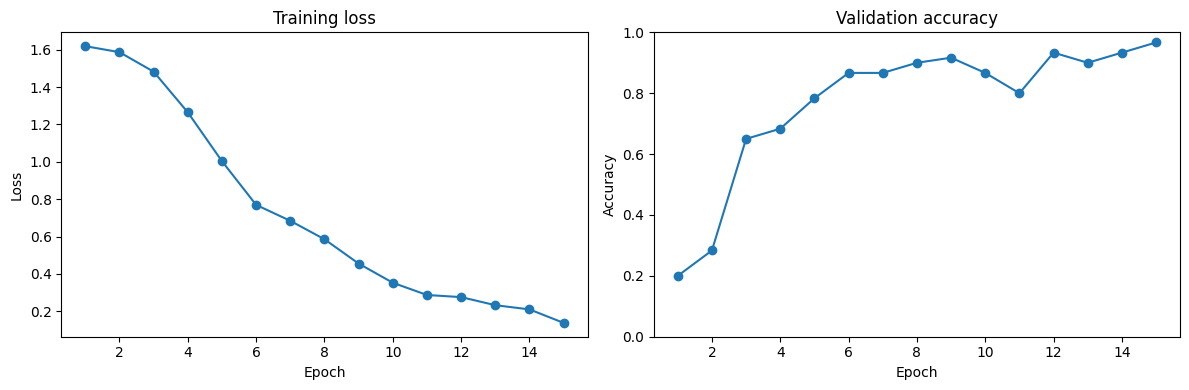

In [48]:
plot_training_history(history)

#### See which participants are confused
This checks predictions on the validation photos and shows which participant pairs the model mixes up.

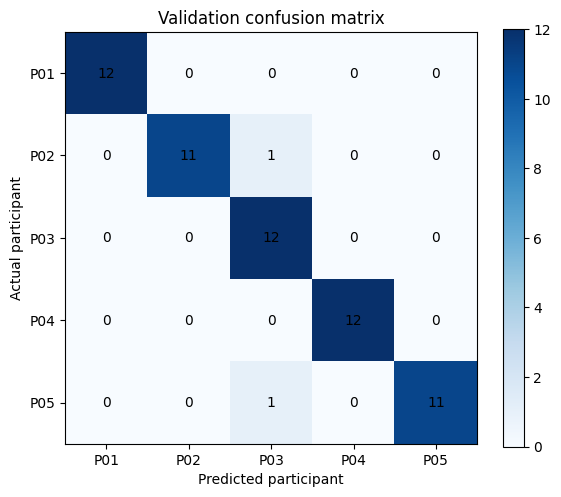

In [49]:
import numpy as np

model.eval()
actual, predicted = [], []

with torch.no_grad():
    for images, labels in validation_loader:
        outputs = model(images.to(device))
        predicted.extend(outputs.argmax(dim=1).cpu().tolist())
        actual.extend(labels.tolist())

class_count = len(dataset.classes)
confusion = np.zeros((class_count, class_count), dtype=int)

for true_label, predicted_label in zip(actual, predicted):
    confusion[true_label, predicted_label] += 1

plt.figure(figsize=(6, 5))
plt.imshow(confusion, cmap="Blues")
plt.xticks(range(class_count), dataset.classes)
plt.yticks(range(class_count), dataset.classes)
plt.xlabel("Predicted participant")
plt.ylabel("Actual participant")
plt.title("Validation confusion matrix")
plt.colorbar()

for row in range(class_count):
    for col in range(class_count):
        plt.text(col, row, confusion[row, col], ha="center", va="center")

plt.tight_layout()
plt.show()

In [50]:
save_training_results(history)

Model saved to: /content/face_recognition_project/models/face_cnn.pth
Labels saved to: /content/face_recognition_project/models/participant_labels.json
Training history saved to: /content/face_recognition_project/results/training_history.csv


#### Check sample predictions
This compares the model’s predictions with the correct labels for five validation photos.

In [51]:
model.eval()

for index in validation_indices[:5]:
    image_path, true_label = dataset.samples[index]

    image = Image.open(image_path).convert("RGB")
    image_tensor = image_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        scores = torch.softmax(model(image_tensor), dim=1)[0]
        predicted_label = scores.argmax().item()
        confidence = scores[predicted_label].item()

    print(
        f"Actual: {dataset.classes[true_label]} | "
        f"Predicted: {dataset.classes[predicted_label]} | "
        f"Confidence: {confidence:.1%} | "
        f"File: {Path(image_path).name}"
    )

Actual: P01 | Predicted: P01 | Confidence: 96.9% | File: IMG20261117133140_tmp.jpg
Actual: P01 | Predicted: P01 | Confidence: 98.9% | File: IMG20261117133424_tmp.jpg
Actual: P01 | Predicted: P01 | Confidence: 99.9% | File: IMG20261117133109_tmp.jpg
Actual: P01 | Predicted: P01 | Confidence: 83.0% | File: IMG20261117133312_tmp.jpg
Actual: P01 | Predicted: P01 | Confidence: 99.9% | File: IMG20261117133111_tmp.jpg


In [52]:
import random

rng = random.Random(7)
model.eval()

for class_id, participant in enumerate(dataset.classes):
    candidates = [
        index for index in validation_indices
        if dataset.targets[index] == class_id
    ]
    index = rng.choice(candidates)
    image_path, true_label = dataset.samples[index]

    image = Image.open(image_path).convert("RGB")
    image_tensor = image_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        scores = torch.softmax(model(image_tensor), dim=1)[0]
        predicted_label = scores.argmax().item()
        confidence = scores[predicted_label].item()

    print(
        f"Actual: {dataset.classes[true_label]} | "
        f"Predicted: {dataset.classes[predicted_label]} | "
        f"Confidence: {confidence:.1%}"
    )

Actual: P01 | Predicted: P01 | Confidence: 53.2%
Actual: P02 | Predicted: P02 | Confidence: 87.0%
Actual: P03 | Predicted: P03 | Confidence: 99.7%
Actual: P04 | Predicted: P04 | Confidence: 97.6%
Actual: P05 | Predicted: P05 | Confidence: 95.4%


In [53]:
import shutil
from google.colab import files

EXPORT_PATH = Path("/content/face_recognition_results.zip")

with zipfile.ZipFile(EXPORT_PATH, "w") as archive:
    for folder in (MODEL_DIR, RESULTS_DIR):
        for file in folder.rglob("*"):
            if file.is_file():
                archive.write(file, file.relative_to(PROJECT_DIR))

files.download(str(EXPORT_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Attendance check
The model will predict their label and add it to the attendance CSV.

In [54]:
uploaded = files.upload()

if uploaded:
    image_name = next(iter(uploaded))
    image_path = Path("/content") / image_name
    record_attendance(image_path, model, dataset.classes, device)

Saving IMG20261117133105_tmp.jpg to IMG20261117133105_tmp.jpg
Attendance recorded: P01 at 2026-11-17T19:09:11


Confirm the attendance log

In [55]:
print(ATTENDANCE_FILE.read_text(encoding="utf-8"))

timestamp,participant,image
2026-11-17T19:09:11,P01,IMG20261117133105_tmp.jpg



The attendance row was saved. Since that photo came from the collected set, it shows the upload-and-log flow works; it may have been used for training, so it doesn’t prove recognition on a new photo.

In [56]:
tested_name = "IMG20261117133105_tmp.jpg"

train_names = {
    Path(dataset.samples[i][0]).name for i in train_indices
}
validation_names = {
    Path(dataset.samples[i][0]).name for i in validation_indices
}

if tested_name in train_names:
    print("This photo was used for training.")
elif tested_name in validation_names:
    print("This photo was held out for validation.")
else:
    print("This photo was not used in training or validation.")

This photo was used for training.


Trying a fresh photo

In [57]:
uploaded = files.upload()

for image_name in uploaded:
    image = Image.open(image_name).convert("RGB")
    image_tensor = image_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        scores = torch.softmax(model(image_tensor), dim=1)[0]
        predicted_index = scores.argmax().item()

    print(
        "Predicted:", dataset.classes[predicted_index],
        "| Confidence:", f"{scores[predicted_index].item():.1%}"
    )

Saving New.jpg to New.jpg
Predicted: P01 | Confidence: 77.9%


Record this attendance

In [58]:
record_attendance(
    Path("/content/New.jpg"),
    model,
    dataset.classes,
    device,
)

Attendance recorded: P01 at 2026-11-17T19:18:04


In [59]:
with zipfile.ZipFile(EXPORT_PATH, "w") as archive:
    for folder in (MODEL_DIR, RESULTS_DIR):
        for file in folder.rglob("*"):
            if file.is_file():
                archive.write(file, file.relative_to(PROJECT_DIR))

files.download(str(EXPORT_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
uploaded = files.upload()

for image_name in uploaded:
    image = Image.open(image_name).convert("RGB")
    image_tensor = image_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        scores = torch.softmax(model(image_tensor), dim=1)[0]
        predicted_index = scores.argmax().item()

    print(
        "Predicted:", dataset.classes[predicted_index],
        "| Confidence:", f"{scores[predicted_index].item():.1%}"
    )

Saving New 2.jpg to New 2.jpg
Predicted: P01 | Confidence: 60.1%


#### Check the model’s scores

In [61]:
for participant, score in zip(dataset.classes, scores.tolist()):
    print(f"{participant}: {score:.1%}")

P01: 60.1%
P02: 39.5%
P03: 0.1%
P04: 0.3%
P05: 0.0%


The new P03 photo was strongly misclassified, so the first model hasn’t learned reliable recognition from new photos.

### Set up improved CNN

In [62]:
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights

weights = MobileNet_V3_Small_Weights.DEFAULT
image_transform = weights.transforms()

dataset = ImageFolder(DATA_DIR, transform=image_transform)

model = mobilenet_v3_small(weights=weights)
model.classifier[3] = nn.Linear(
    model.classifier[3].in_features,
    len(dataset.classes),
)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

print("Pretrained CNN ready for", dataset.classes)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 44.1MB/s]


Pretrained CNN ready for ['P01', 'P02', 'P03', 'P04', 'P05']


#### Rebuild the balanced data loaders
This recreates the 60-per-participant training and validation split using the new image preprocessing.

In [63]:
rng = random.Random(42)
train_indices, validation_indices = [], []

for class_id, participant in enumerate(dataset.classes):
    class_indices = [
        i for i, label in enumerate(dataset.targets)
        if label == class_id
    ]
    rng.shuffle(class_indices)

    selected = class_indices[:EXPECTED_IMAGES_PER_PERSON]
    validation_count = round(len(selected) * VALIDATION_FRACTION)

    validation_indices.extend(selected[:validation_count])
    train_indices.extend(selected[validation_count:])

train_loader = DataLoader(
    Subset(dataset, train_indices),
    batch_size=BATCH_SIZE,
    shuffle=True,
)
validation_loader = DataLoader(
    Subset(dataset, validation_indices),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("Training photos:", len(train_indices))
print("Validation photos:", len(validation_indices))

Training photos: 240
Validation photos: 60


#### Train the improved CNN
This fine-tunes the pretrained model on your balanced photos and reports validation accuracy each round.

In [64]:
EPOCHS = 10

history = train_model(
    model,
    train_loader,
    validation_loader,
    criterion,
    optimizer,
    device,
    EPOCHS,
)

Epoch 1/10 | loss: 1.4631 | validation accuracy: 45.0%
Epoch 2/10 | loss: 0.9375 | validation accuracy: 68.3%
Epoch 3/10 | loss: 0.5636 | validation accuracy: 86.7%
Epoch 4/10 | loss: 0.2892 | validation accuracy: 90.0%
Epoch 5/10 | loss: 0.1765 | validation accuracy: 95.0%
Epoch 6/10 | loss: 0.0960 | validation accuracy: 96.7%
Epoch 7/10 | loss: 0.0660 | validation accuracy: 100.0%
Epoch 8/10 | loss: 0.0393 | validation accuracy: 100.0%
Epoch 9/10 | loss: 0.0357 | validation accuracy: 100.0%
Epoch 10/10 | loss: 0.0349 | validation accuracy: 100.0%


The validation accuracy reached 100%, but the real check is whether the model now recognizes the fresh P03 photo it misclassified earlier.

#### Retest the fresh P03 photo

In [65]:
test_image = Image.open("/content/New 2.jpg").convert("RGB")
test_tensor = image_transform(test_image).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    scores = torch.softmax(model(test_tensor), dim=1)[0]
    predicted_index = scores.argmax().item()

print(
    "Predicted:", dataset.classes[predicted_index],
    "| Confidence:", f"{scores[predicted_index].item():.1%}"
)

Predicted: P02 | Confidence: 30.2%


The improved CNN still classified the fresh P03 photo as P02, so the model isn’t ready to record attendance. Switch to a face recognition CNN that first detects and aligns faces, then compares their face features.

#### Install the face recognition tools

In [67]:
!pip -q install --no-deps facenet-pytorch
from facenet_pytorch import MTCNN, InceptionResnetV1

print("Face recognition tools are ready.")

Face recognition tools are ready.


#### Load the face models
This loads the face detector and pretrained FaceNet recognition model.

In [68]:
mtcnn = MTCNN(
    image_size=160,
    margin=20,
    keep_all=True,
    device=device,
)

facenet = InceptionResnetV1(
    pretrained="vggface2"
).eval().to(device)

print("Face detection and recognition models are ready.")

  0%|          | 0.00/107M [00:00<?, ?B/s]

Face detection and recognition models are ready.


#### Set up enrollment face detection
For the participant folders, we’ll detect the main face in each photo.

In [69]:
enrollment_detector = MTCNN(
    image_size=160,
    margin=20,
    keep_all=False,
    device=device,
)

print("Enrollment face detector is ready.")

Enrollment face detector is ready.


#### Create participant face profiles
This detects and converts up to 60 photos per participant into face feature vectors, then averages them into a profile for recognition.

In [70]:
face_profiles = {}
embedding_rng = random.Random(42)

for participant in PARTICIPANTS:
    folder = DATA_DIR / participant
    image_paths = [
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    ]
    image_paths = embedding_rng.sample(
        image_paths,
        min(EXPECTED_IMAGES_PER_PERSON, len(image_paths)),
    )

    embeddings = []
    for image_path in image_paths:
        image = Image.open(image_path).convert("RGB")
        face = enrollment_detector(image)

        if face is not None:
            with torch.no_grad():
                embedding = facenet(face.unsqueeze(0).to(device))
                embeddings.append(embedding.squeeze(0).cpu())

    if embeddings:
        face_profiles[participant] = torch.nn.functional.normalize(
            torch.stack(embeddings).mean(dim=0),
            dim=0,
        )

    print(f"{participant}: {len(embeddings)}/{len(image_paths)} faces processed")

print("Profiles ready for:", list(face_profiles))

P01: 60/60 faces processed
P02: 59/60 faces processed
P03: 60/60 faces processed
P04: 60/60 faces processed
P05: 47/60 faces processed
Profiles ready for: ['P01', 'P02', 'P03', 'P04', 'P05']


The face-specific detector processed most enrollment photos, though it missed some in P02 and P05.

#### Retest the fresh P03 photo

In [71]:
test_image = Image.open("/content/New 2.jpg").convert("RGB")
detected_faces = mtcnn(test_image)

if detected_faces is None:
    print("No face detected in this photo.")
else:
    if detected_faces.ndim == 3:
        detected_faces = detected_faces.unsqueeze(0)

    with torch.no_grad():
        embeddings = facenet(detected_faces.to(device))
        embeddings = torch.nn.functional.normalize(embeddings, dim=1)

    profile_names = list(face_profiles)
    profile_matrix = torch.stack(
        [face_profiles[name] for name in profile_names]
    ).to(device)

    for face_number, embedding in enumerate(embeddings):
        similarities = profile_matrix @ embedding
        best_index = similarities.argmax().item()

        print(
            f"Face {face_number + 1}: {profile_names[best_index]} "
            f"(similarity {similarities[best_index].item():.3f})"
        )

Face 1: P03 (similarity 0.814)


the face specific model correctly matched the fresh P03 photo.

#### Prepare the face recognition function
Adjusted to identify every detected face in a photo, including a group photo.

In [72]:
def recognize_photo(image_path):
    image = Image.open(image_path).convert("RGB")
    faces = mtcnn(image)

    if faces is None:
        print("No faces detected.")
        return []

    if faces.ndim == 3:
        faces = faces.unsqueeze(0)

    with torch.no_grad():
        embeddings = facenet(faces.to(device))
        embeddings = torch.nn.functional.normalize(embeddings, dim=1)

    names = list(face_profiles)
    profiles = torch.stack([face_profiles[name] for name in names]).to(device)
    results = []

    for face_number, embedding in enumerate(embeddings, start=1):
        similarities = profiles @ embedding
        best = similarities.argmax().item()
        result = (names[best], similarities[best].item())
        results.append(result)
        print(
            f"Face {face_number}: {result[0]} "
            f"(similarity {result[1]:.3f})"
        )

    return results

recognize_photo("/content/New.jpg")

Face 1: P01 (similarity 0.859)


[('P01', 0.8591978549957275)]

The FaceNet model matched the fresh P03 and P01 photos correctly.

#### Add a FaceNet attendance logger
This accepts matches at or above 0.70 similarity and records them in a separate CSV. It avoids changing the earlier test log.

In [73]:
import csv
from datetime import datetime

FACENET_ATTENDANCE_FILE = RESULTS_DIR / "facenet_attendance.csv"
MATCH_THRESHOLD = 0.70

def log_face_attendance(image_path):
    matches = recognize_photo(image_path)
    timestamp = datetime.now().isoformat(timespec="seconds")
    logged_today = set()

    if FACENET_ATTENDANCE_FILE.exists():
        with FACENET_ATTENDANCE_FILE.open(encoding="utf-8") as file:
            for row in csv.DictReader(file):
                if row["timestamp"][:10] == timestamp[:10]:
                    logged_today.add(row["participant"])

    new_rows = []
    for participant, similarity in matches:
        if similarity < MATCH_THRESHOLD:
            print(f"Uncertain match ({similarity:.3f}); not recorded.")
        elif participant in logged_today:
            print(f"{participant} is already recorded today.")
        else:
            new_rows.append([timestamp, participant, f"{similarity:.3f}",
                             Path(image_path).name])
            logged_today.add(participant)

    if new_rows:
        write_header = not FACENET_ATTENDANCE_FILE.exists()
        with FACENET_ATTENDANCE_FILE.open("a", newline="", encoding="utf-8") as file:
            writer = csv.writer(file)
            if write_header:
                writer.writerow(["timestamp", "participant", "similarity", "image"])
            writer.writerows(new_rows)
        print("Attendance recorded:", ", ".join(row[1] for row in new_rows))

Record a test match

In [74]:
log_face_attendance("/content/New 2.jpg")

Face 1: P03 (similarity 0.814)
Attendance recorded: P03


### Upload-and-attendance bot
This lets you upload a participant photo or group photo. The bot detects faces, matches them to participant profiles, and records matches above the current cutoff.

In [75]:
def run_face_attendance_bot():
    uploaded = files.upload()

    for image_name in uploaded:
        if Path(image_name).suffix.lower() in IMAGE_EXTENSIONS:
            log_face_attendance(Path("/content") / image_name)

print("Attendance bot is ready. Run run_face_attendance_bot() to use it.")

Attendance bot is ready. Run run_face_attendance_bot() to use it.


In [76]:
run_face_attendance_bot()

Saving P2 new 2.jpg to P2 new 2.jpg
Face 1: P02 (similarity 0.832)
Attendance recorded: P02


The bot correctly matched and recorded the fresh P02 photo.

In [77]:
profile_path = MODEL_DIR / "facenet_profiles.pth"

torch.save({
    "face_profiles": face_profiles,
    "participants": list(face_profiles),
    "match_threshold": MATCH_THRESHOLD,
}, profile_path)

with zipfile.ZipFile(EXPORT_PATH, "w") as archive:
    for folder in (MODEL_DIR, RESULTS_DIR):
        for file in folder.rglob("*"):
            if file.is_file():
                archive.write(file, file.relative_to(PROJECT_DIR))

files.download(str(EXPORT_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The FaceNet attendance bot is running.

To use it, run: **run_face_attendance_bot()**

It will ask you to upload a photo, identify each detected face, and record matches above the current 0.70 similarity cutoff. The P02 and P03 fresh-photo checks were matched correctly.

Test a group photo

In [78]:
uploaded = files.upload()

for image_name in uploaded:
    recognize_photo(Path("/content") / image_name)

Saving P3 group.jpg to P3 group.jpg
Face 1: P03 (similarity 0.790)
Face 2: P03 (similarity 0.553)
Face 3: P03 (similarity 0.560)


Label weak matches clearly

In [80]:
def recognize_photo(image_path):
    image = Image.open(image_path).convert("RGB")
    faces = mtcnn(image)

    if faces is None:
        print("No faces detected.")
        return []

    if faces.ndim == 3:
        faces = faces.unsqueeze(0)

    with torch.no_grad():
        embeddings = facenet(faces.to(device))
        embeddings = torch.nn.functional.normalize(embeddings, dim=1)

    names = list(face_profiles)
    profiles = torch.stack([face_profiles[name] for name in names]).to(device)
    results = []

    for face_number, embedding in enumerate(embeddings, start=1):
        similarities = profiles @ embedding
        best = similarities.argmax().item()
        score = similarities[best].item()
        label = names[best] if score >= MATCH_THRESHOLD else "Unknown / review"

        print(f"Face {face_number}: {label} (similarity {score:.3f})")
        results.append((names[best], score))

    return results

In [81]:
recognize_photo("/content/P3 group.jpg")

Face 1: P03 (similarity 0.790)
Face 2: Unknown / review (similarity 0.553)
Face 3: Unknown / review (similarity 0.560)


[('P03', 0.789784848690033),
 ('P03', 0.5531788468360901),
 ('P03', 0.5597798228263855)]

In [82]:
log_face_attendance("/content/P3 group.jpg")

Face 1: P03 (similarity 0.790)
Face 2: Unknown / review (similarity 0.553)
Face 3: Unknown / review (similarity 0.560)
P03 is already recorded today.
Uncertain match (0.553); not recorded.
Uncertain match (0.560); not recorded.


The group-photo attendance check worked: P03 was recognized, the two weak matches were not recorded, and duplicate attendance was prevented.

The core prototype is working. It detects faces, matches them to the five participant profiles, and records attendance. We tested fresh P01 and P03 photos successfully, and a group photo produced one P03 match plus two low similarity faces that were left unrecorded.

#### Evaluate the recognizer on fresh photos

In [87]:
fresh_tests = [
    ("/content/New.jpg", "P01"),
    ("/content/P2 new 2.jpg", "P02"),
    ("/content/New 2.jpg", "P03"),
]

evaluation_rows = []

for image_path, expected in fresh_tests:
    if not Path(image_path).exists():
        print("Photo not found:", image_path)
        continue

    matches = recognize_photo(image_path)

    if matches:
        predicted, similarity = matches[0]
        accepted = predicted if similarity >= MATCH_THRESHOLD else "Unknown"
    else:
        predicted, similarity, accepted = "No face", 0.0, "Unknown"

    evaluation_rows.append({
        "expected": expected,
        "predicted": accepted,
        "similarity": round(similarity, 3),
        "correct": accepted == expected,
    })

evaluation_table = pd.DataFrame(evaluation_rows)
display(evaluation_table)

print(
    "Fresh-photo accuracy:",
    f"{evaluation_table['correct'].mean():.1%}"
    if len(evaluation_table) else "No photos evaluated",
)

Face 1: P01 (similarity 0.859)
Face 1: P02 (similarity 0.832)
Face 1: P03 (similarity 0.814)


,expected,predicted,similarity,correct
0,P01,P01,0.859,True
1,P02,P02,0.832,True
2,P03,P03,0.814,True


Fresh-photo accuracy: 100.0%


#### Evaluate all five participants with held-out photos

In [90]:
rng = random.Random(123)
profile_paths, test_paths = {}, {}

for person in PARTICIPANTS:
    folder = DATA_DIR / person
    paths = sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    paths = rng.sample(paths, min(60, len(paths)))
    rng.shuffle(paths)
    n_test = max(1, round(len(paths) * 0.2))
    test_paths[person] = paths[:n_test]
    profile_paths[person] = paths[n_test:]

def get_embedding(path):
    face = enrollment_detector(Image.open(path).convert("RGB"))
    if face is None:
        return None
    with torch.no_grad():
        vector = facenet(face.unsqueeze(0).to(device)).squeeze(0)
    return torch.nn.functional.normalize(vector, dim=0).cpu()

holdout_profiles = {}
for person in PARTICIPANTS:
    vectors = [
        vector for path in profile_paths[person]
        if (vector := get_embedding(path)) is not None
    ]
    if vectors:
        holdout_profiles[person] = torch.nn.functional.normalize(
            torch.stack(vectors).mean(dim=0), dim=0
        )

profile_names = list(holdout_profiles)
profile_matrix = torch.stack(
    [holdout_profiles[name] for name in profile_names]
)

rows = []
for person in PARTICIPANTS:
    for path in test_paths[person]:
        vector = get_embedding(path)

        if vector is None:
            predicted, score = "No face", 0.0
        else:
            scores = profile_matrix @ vector
            best = scores.argmax().item()
            score = scores[best].item()
            predicted = profile_names[best]
            if score < MATCH_THRESHOLD:
                predicted = "Unknown"

        rows.append({
            "expected": person,
            "predicted": predicted,
            "similarity": round(score, 3),
            "correct": predicted == person,
        })

holdout_table = pd.DataFrame(rows)
display(holdout_table.groupby("expected").agg(
    test_photos=("expected", "size"),
    correct=("correct", "sum"),
    mean_similarity=("similarity", "mean"),
))
print("Overall held-out accuracy:", f"{holdout_table['correct'].mean():.1%}")

,test_photos,correct,mean_similarity
expected,,,
P01,12,12,0.919500
P02,12,12,0.903667
P03,12,12,0.924667
P04,12,12,0.928083
P05,12,11,0.822250


Overall held-out accuracy: 98.3%


In [91]:
display(holdout_table[holdout_table["correct"] == False])

holdout_table.to_csv(
    RESULTS_DIR / "held_out_evaluation.csv",
    index=False,
)

,expected,predicted,similarity,correct
49,P05,No face,0.0,False


#### Evaluation results
On a balanced internal holdout of 60 photos—12 per participant—the detector found a face in 59 photos. All 59 detected faces matched the correct participant at the 0.70 similarity cutoff. One P05 photo had no detected face, so the system returned “No face.” This gives 59/60 (98.3%) end-to-end successful matches on this split, and 59/59 correct identifications among photos where a face was detected.

The system also matched the three fresh photos tested for P01, P02, and P03. In a group photo, it matched one face to P03 and marked two low-similarity faces for review. The internal holdout uses photos from the same collection, so these results do not show how well the system performs across different sessions or conditions. Further fresh-photo testing is needed, especially for P04 and P05.

In [92]:
baseline_rows = [
    {"epoch": 1, "loss": 1.6188, "validation_accuracy": 0.200},
    {"epoch": 2, "loss": 1.5867, "validation_accuracy": 0.283},
    {"epoch": 3, "loss": 1.4822, "validation_accuracy": 0.650},
    {"epoch": 4, "loss": 1.2647, "validation_accuracy": 0.683},
    {"epoch": 5, "loss": 1.0032, "validation_accuracy": 0.783},
    {"epoch": 6, "loss": 0.7696, "validation_accuracy": 0.867},
    {"epoch": 7, "loss": 0.6843, "validation_accuracy": 0.867},
    {"epoch": 8, "loss": 0.5857, "validation_accuracy": 0.900},
    {"epoch": 9, "loss": 0.4556, "validation_accuracy": 0.917},
    {"epoch": 10, "loss": 0.3531, "validation_accuracy": 0.867},
    {"epoch": 11, "loss": 0.2875, "validation_accuracy": 0.800},
    {"epoch": 12, "loss": 0.2762, "validation_accuracy": 0.933},
    {"epoch": 13, "loss": 0.2330, "validation_accuracy": 0.900},
    {"epoch": 14, "loss": 0.2105, "validation_accuracy": 0.933},
    {"epoch": 15, "loss": 0.1383, "validation_accuracy": 0.967},
]

pd.DataFrame(baseline_rows).to_csv(
    RESULTS_DIR / "baseline_cnn_history.csv", index=False
)
pd.DataFrame(history).to_csv(
    RESULTS_DIR / "mobilenet_history.csv", index=False
)

print("Saved baseline CNN and MobileNet training histories.")

Saved baseline CNN and MobileNet training histories.


## Model development
I first trained a small CNN from scratch for 15 epochs. It reached 96.7% validation accuracy, but misclassified a fresh P03 photo as P01. I then fine-tuned a pretrained MobileNetV3 for 10 epochs. It reached 100% validation accuracy but still misclassified that fresh P03 photo as P02. These results showed that validation accuracy on this dataset did not reliably predict performance on new photos.

For the final prototype, I used MTCNN for face detection and alignment, then a pretrained FaceNet InceptionResnetV1 model to produce face embeddings. I created a reference profile for each participant by averaging embeddings from their enrollment photos. The bot matches detected faces to these profiles using cosine similarity and marks scores below 0.70 for review. This final recognition pipeline uses a pretrained CNN; it does not train FaceNet from scratch on the five participants’ photos.

In [93]:
# Save the per-photo evaluation results
holdout_table.to_csv(
    RESULTS_DIR / "held_out_evaluation.csv",
    index=False,
)

evaluation_table.to_csv(
    RESULTS_DIR / "fresh_photo_evaluation.csv",
    index=False,
)

# Summarize held-out performance
total_photos = len(holdout_table)
faces_detected = (holdout_table["predicted"] != "No face").sum()
correct_matches = holdout_table["correct"].sum()

detection_rate = faces_detected / total_photos if total_photos else 0
match_rate_when_face_detected = (
    correct_matches / faces_detected if faces_detected else 0
)
overall_success = correct_matches / total_photos if total_photos else 0

print(f"Held-out photos: {total_photos}")
print(f"Faces detected: {faces_detected}/{total_photos} ({detection_rate:.1%})")
print(
    "Correct identity when a face was detected:",
    f"{correct_matches}/{faces_detected} ({match_rate_when_face_detected:.1%})",
)
print(f"Overall successful matches: {correct_matches}/{total_photos} ({overall_success:.1%})")

print("\nResults by participant:")
display(holdout_table.groupby("expected").agg(
    test_photos=("expected", "size"),
    faces_detected=("predicted", lambda values: (values != "No face").sum()),
    correct_matches=("correct", "sum"),
))

print("\nHeld-out predictions:")
display(pd.crosstab(
    holdout_table["expected"],
    holdout_table["predicted"],
    rownames=["Expected"],
    colnames=["Predicted"],
    dropna=False,
))

print("\nFresh-photo checks:")
display(evaluation_table)

Held-out photos: 60
Faces detected: 59/60 (98.3%)
Correct identity when a face was detected: 59/59 (100.0%)
Overall successful matches: 59/60 (98.3%)

Results by participant:


,test_photos,faces_detected,correct_matches
expected,,,
P01,12,12,12
P02,12,12,12
P03,12,12,12
P04,12,12,12
P05,12,11,11



Held-out predictions:


Predicted,No face,P01,P02,P03,P04,P05
Expected,,,,,,
P01,0,12,0,0,0,0
P02,0,0,12,0,0,0
P03,0,0,0,12,0,0
P04,0,0,0,0,12,0
P05,1,0,0,0,0,11



Fresh-photo checks:


,expected,predicted,similarity,correct
0,P01,P01,0.859,True
1,P02,P02,0.832,True
2,P03,P03,0.814,True


In [94]:
import json

PROFILE_PATH = MODEL_DIR / "facenet_profiles.pth"
CONFIG_PATH = MODEL_DIR / "facenet_config.json"
FINAL_EXPORT_PATH = PROJECT_DIR / "face_recognition_final_results.zip"

torch.save({
    "face_profiles": face_profiles,
    "participants": list(face_profiles),
    "match_threshold": MATCH_THRESHOLD,
}, PROFILE_PATH)

config = {
    "face_detector": "MTCNN",
    "recognition_model": "InceptionResnetV1 pretrained on VGGFace2",
    "similarity_threshold": MATCH_THRESHOLD,
    "enrollment_limit_per_participant": EXPECTED_IMAGES_PER_PERSON,
}
CONFIG_PATH.write_text(json.dumps(config, indent=2), encoding="utf-8")

export_files = [
    PROFILE_PATH,
    CONFIG_PATH,
    RESULTS_DIR / "facenet_attendance.csv",
    RESULTS_DIR / "dataset_eda_summary.csv",
    RESULTS_DIR / "baseline_cnn_history.csv",
    RESULTS_DIR / "mobilenet_history.csv",
    RESULTS_DIR / "held_out_evaluation.csv",
    RESULTS_DIR / "fresh_photo_evaluation.csv",
]

with zipfile.ZipFile(FINAL_EXPORT_PATH, "w") as archive:
    for path in export_files:
        if path.exists():
            archive.write(path, path.relative_to(PROJECT_DIR))
        else:
            print("Not found, skipped:", path.name)

files.download(str(FINAL_EXPORT_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Conclusion
This project produced a prototype attendance system for five enrolled participants. The final pipeline uses MTCNN to detect and align faces, then compares FaceNet embeddings with participant profiles using a 0.70 similarity cutoff. The profiles use up to 60 enrollment photos per participant.

On the internal holdout, the system detected faces in 59 of 60 photos and matched all 59 detected faces correctly. It also matched the three fresh photos tested for P01, P02, and P03. In a group photo, it matched one face to P03 and marked two low-similarity faces for review.

These results are promising for this dataset, but the internal holdout came from the same photo collection. Fresh-photo testing covered only P01, P02, and P03, and one held-out P05 photo had no face detected. The system should therefore be treated as an academic prototype; its results may not carry over to different people, cameras, or conditions.